# Train RecurrentSurrogate on multilayer spectra

An example training workflow using the current iBeamLab API.
Each layer has **one elemental areal-density input per element**, with no extra
total-thickness input: $N_e = N_\mathrm{layer}c_e$. Physical AD is in
$10^{15}$ atoms/cm² and is multiplied once by `ad_input_factor`.

One shared RecurrentSurrogate learns all selected layer counts; each detector has its own
spectrum head and output processing. Preparation streams completed datasets
into disk-backed arrays. Training and evaluation read bounded minibatches.

Use a Python kernel with `torch`, `numpy`, `tqdm`, `matplotlib`, `onnx` and
`onnxruntime` installed. Notebook support requires `jupyterlab` or `ipykernel`.
Choose paths and settings below before running the remaining cells.

In [5]:
from pathlib import Path
import json
import sys

# Locate the checkout from either the repository root or this notebook's folder.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "CMakeLists.txt").is_file()
             and (p / "ibeamlab").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter inside the iBeamLab checkout")
sys.path.insert(0, str(ROOT))

# Change to an ONNX-enabled build for native deployment verification.
# Set None to use the installed extension instead.
EXTENSION_DIR = ROOT / "build/local/Release/bin"
if EXTENSION_DIR is not None:
    if not EXTENSION_DIR.is_dir():
        raise FileNotFoundError(EXTENSION_DIR)
    sys.path.insert(0, str(EXTENSION_DIR))

import numpy as np
import matplotlib.pyplot as plt
import torch
import ibeamlab as ibl
from examples.ibeamnet.validation import validate_training, validate_checkpoint_contract
from examples.ibeamnet.workflow import load_cache
from examples.ibeamnet.data import digest
from examples.ibeamnet.training import train, make_model, load_checkpoint, resolve_resume
from examples.ibeamnet.deployment import export

print("Repository:", ROOT)
print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "CUDA available:", torch.cuda.is_available())

Repository: D:\ibeamlab
Python: c:\Users\local_admin\.conda\envs\DL\python.exe
PyTorch: 2.3.1 CUDA available: True


## 1. Dataset and preprocessing settings

Configure source datasets, element order, scaling and cache location in plain Python here.
This notebook does not read surrogate.toml; the CLI may still use TOML.
SCHEMA_CHECKPOINT selects compatible architecture/output dimensions when using
pretrained weights. Changing that scientific schema requires a matching cache.
Selecting weights for the actual training run happens in the training cell.

Training controls are all in section 4. Changing the schedule, device or run
mode does not require rerunning these cells or data preparation. Completed caches
are memory-mapped; training never reloads all spectra into RAM.

In [6]:
# Notebook settings are plain Python; no TOML file is read.
config = {
    "format": "ibeamlab.surrogate", "format_version": 1,
    "data": {
        "source": ROOT / "examples/DataGeneration/datasets/iba_multilayer_13el",
        "cache": ROOT / "examples/ibeamnet/cache",
        "layer_counts": list(range(1, 9)),
        "max_records_per_source": 0,
        "validation_fraction": 0.1, "test_fraction": 0.1, "seed": 42,
    },
    "preprocessing": {"ad_input_factor": 1e-4},
    "spectra": [{"measurement": "RBS", "count_scale": 100.0, "loss_weight": 1.0,
                 "exposure_scale": True, "rebin": True}],
}
# Omit channels to infer each detector's maximum length when preparing a cache.

# Optional scientific schema selection. It selects the saved architecture,
# ordered spectrum schema and AD scaling before preparing the training cache.
RUN_DIRECTORY = ROOT / "examples/ibeamnet/runs/forward"
SCHEMA_CHECKPOINT = RUN_DIRECTORY / "last.pt"
if SCHEMA_CHECKPOINT is not None:
    initial = load_checkpoint(SCHEMA_CHECKPOINT)
    config["model"] = initial["model_options"]
    config["spectra"] = initial["spectra"]
    config["preprocessing"]["ad_input_factor"] = initial["ad_input_factor"]
    saved_run = json.loads((RUN_DIRECTORY / "run.json").read_text())
    config["data"]["cache"] = Path(saved_run["cache"])  # Reuse the existing training cache.
    print("Schema checkpoint:", SCHEMA_CHECKPOINT)
    print("Initial weight elements:", initial["elements"])

# Dataset and cache settings. Uncomment to customize.
# config["data"]["source"] = ROOT / "examples/DataGeneration/datasets/iba_multilayer_13el"
# config["data"]["layer_counts"] = [1, 2]
# config["data"]["max_records_per_source"] = 1000
# config["data"]["cache"] = ROOT / "examples/ibeamnet/cache-small"
# config["preprocessing"]["ad_input_factor"] = 1e-4

CACHE = Path(config["data"]["cache"])
for key in ("source", "cache", "layer_counts", "max_records_per_source"):
    print(f"{key}: {config['data'][key]}")
print("AD input factor:", config["preprocessing"]["ad_input_factor"])
print("Detector outputs:", config["spectra"])

Schema checkpoint: D:\ibeamlab\examples\ibeamnet\runs\forward\last.pt
Initial weight elements: ['Li', 'Ni', 'Mn', 'Co', 'O', 'C', 'F', 'P', 'Cu', 'Al', 'Si', 'Na', 'Fe']
source: D:\ibeamlab\examples\DataGeneration\datasets\iba_multilayer_13el
cache: D:\ibeamlab\examples\ibeamnet\cache-initial-d6c940353996
layer_counts: [1, 2, 3, 4, 5, 6, 7, 8]
max_records_per_source: 0
AD input factor: 0.0001
Detector outputs: [{'measurement': 'RBS', 'channels': 2998, 'count_scale': 100.0, 'loss_weight': 1.0, 'exposure_scale': True, 'rebin': True}]


## 2. Prepare or reuse a completed cache

Input arrays have shape `[samples, maximum_layers, elements]`; absent layers
are zero-padded. Spectra are padded independently to each configured width;
nonzero tails are rejected. Train/validation/test splits are seeded per layer
count, with all detector spectra from one sample kept in the same split.

An incomplete cache is never reused. Preparation does not modify source datasets.

In [7]:
manifest = load_cache(config, prepare_if_missing=True)

print("Records:", f"{manifest['records']:,}")
print("Cached splits (holdout caps applied when training starts):", manifest["split_sizes"])
print("Elements:", manifest["elements"])
print("Network inputs per layer:", len(manifest["elements"]))
print("Input representation:", manifest["input_representation"])

Records: 2,660,000
Cached splits (holdout caps applied when training starts): {'train': 2128000, 'validation': 266000, 'test': 266000}
Elements: ['Li', 'Ni', 'Mn', 'Co', 'O', 'C', 'F', 'P', 'Cu', 'Al', 'Si', 'Na', 'Fe']
Network inputs per layer: 13
Input representation: scaled_elemental_areal_density


## 3. Inspect spectra and areal-density distributions

Only a bounded selection of training rows is copied for plots. Counts are
shown before and after scaling; input histograms show physical elemental AD
summed over the sample's layers. Padding remains exactly zero.

In [ ]:
features = np.load(CACHE / "features.npy", mmap_mode="r")
targets = np.load(CACHE / "targets.npy", mmap_mode="r")
train_indices = np.load(CACHE / "train_indices.npy", mmap_mode="r")
representative = int(train_indices[len(train_indices) // 2])
fig, axes = plt.subplots(len(manifest["spectra"]), 2, figsize=(13, 4 * len(manifest["spectra"])), squeeze=False)
offset = 0
for row, spec in enumerate(manifest["spectra"]):
    stop = offset + spec["channels"]
    scaled = np.array(targets[representative, offset:stop])
    axes[row, 0].plot(scaled * spec["count_scale"])
    axes[row, 0].set(title=f"{spec['measurement']}: physical counts", xlabel="Channel", ylabel="Counts")
    axes[row, 1].plot(scaled)
    axes[row, 1].set(title=f"Counts / {spec['count_scale']:g}", xlabel="Channel", ylabel="Scaled counts")
    offset = stop
fig.tight_layout()
plt.show()

positions = np.linspace(0, len(train_indices) - 1, min(4096, len(train_indices)), dtype=np.int64)
totals = features[train_indices[positions]].sum(axis=1) / manifest["ad_input_factor"]
columns = 4
rows = (len(manifest["elements"]) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(14, 3 * rows), squeeze=False)
for index, element in enumerate(manifest["elements"]):
    axes.flat[index].hist(totals[:, index], bins=40)
    axes.flat[index].set(title=element, xlabel="Sample AD (1e15 atoms/cm²)", ylabel="Samples")
for axis in axes.flat[len(manifest["elements"]):]:
    axis.set_visible(False)
fig.tight_layout()
plt.show()
del totals

## 4. Train or resume

All loop controls are in the next cell. Edit and rerun only that cell to change
the schedule or continue a run; the existing cache and inspection arrays stay
available. Training opens bounded memory maps, without preparing source data again.

RESUME_TRAINING="auto" resumes when RUN/last.pt exists, otherwise starts a new
run in a new directory. True requires an existing training checkpoint; False
requires a new directory. Existing directories without last.pt are rejected.
An initial weights file does not contain the optimizer state needed for resume.

The staged schedule describes the TOTAL run, including completed epochs.
AdamW moments continue between stages. Training controls may change on resume, including batch size, workers, device,
weight decay, gradient clipping, seed and loss. AdamW moments are retained.
Changing the loss reevaluates the protected best under the new objective.
Model architecture and cached scientific inputs must remain compatible.
There is no automatic learning-rate reduction or early stopping.

INITIAL_WEIGHTS selects compatible weights for a new run, or None starts from
scratch. On resume it is ignored in favor of the run's saved weights and AdamW
state. SCHEMA_CHECKPOINT above only selected cache-compatible dimensions.
best.pt protects the best validation model, including the initial baseline;
last.pt saves optimizer/random states and progress. Ctrl+C finishes the active
optimizer step, writes last.pt and interrupted.pt, and returns without running
held-out testing. Resume continues the saved shuffle after completed batches.
A forced interruption inside an operation saves a snapshot and leaves the last
safe resumable state intact. Held-out test data never selects the model or rates.
Startup reports the loaded weights, device, sample counts, target scales, current
validation loss before updates, and protected best loss. Optimization still uses
the entire training pool. Reported train loss evaluates 20,000 fixed random
training samples; validation uses at most 20,000 fixed validation samples.
Both use frozen end-of-epoch weights and batches of 2,048. Smaller pools use all
records. Membership is saved in checkpoints and reused every epoch and on resume.
The online optimizer loss is kept separately as optimization_loss. An older
run's protected best is reevaluated if its evaluation policy differs.
All prefetch controls are in the training cell. Workers=0 uses synchronous
memory-map reads; workers>0 enables configured prefetch and persistent workers.
Only 20,000 validation and 10,000 test records are reserved. Every other cached
record is available for optimizer training (2,630,000 out of 2,660,000). Existing
caches use run-local split indices; no spectra are rebuilt or discarded.

In [10]:
# Refresh Python training helpers without restarting the kernel or touching data.
from importlib import reload
from examples.ibeamnet import training as training_workflow
training_workflow = reload(training_workflow)
train, resolve_resume = training_workflow.train, training_workflow.resolve_resume

# All editable training-loop controls live here. No data preparation in this cell.
RESUME_TRAINING = True  # Continue this run's last.pt, including AdamW and epoch progress.
RUN = ROOT / "examples/ibeamnet/runs/forward"  # Choose a new folder for a new run.
INITIAL_WEIGHTS = None  # Exact resume loads last.pt; no reference weights or warm start.
# Set INITIAL_WEIGHTS to a compatible checkpoint path, or None for random initialization.

# TOTAL schedule, including completed epochs. Edit here when extending a run.
TRAINING_SCHEDULE = [
    #{'learning_rate': 0.00005, 'epochs': 100},
    {'learning_rate': 1e-06, 'epochs': 120},
]
BATCH_SIZE = 512  # Optimizer minibatch size; the entire training pool is used.
TRAIN_EVALUATION_SAMPLES = 20000  # Fixed random training subset, chosen once.
VALIDATION_SAMPLES = 20000  # Total validation holdout cap.
TEST_SAMPLES = 10000  # Total test holdout cap; all surplus records return to training.
EVALUATION_BATCH_SIZE = 2048  # Frozen-model train/validation evaluations each epoch.
EVALUATION_WORKERS = 0  # Avoid extra worker pools for these small evaluation subsets.
DEVICE = 'auto'  # auto, cpu, cuda, cuda:0.
WORKERS = 4  # Safe for Windows/Jupyter; >0 enables worker prefetch.
PREFETCH_FACTOR = 4  # Batches per worker; applies only when WORKERS > 0.
PERSISTENT_WORKERS = True  # Keep worker processes across epochs when WORKERS > 0.
WEIGHT_DECAY = 1e-05
GRADIENT_CLIP = 5.0
TRAINING_SEED = 42
LOSS_OPTIONS = {'kind': 'chi_square', 'noise_floor': 1.0}
# A selected schema checkpoint supplies its proven architecture. Otherwise use these defaults.
MODEL_OPTIONS = dict(config.get("model", {
    "hidden_size": 256, "embedding_size": 128, "setup_embedding_size": 32,
    "contribution_size": 512, "block_hidden_sizes": [512, 512],
    "decoder_hidden_sizes": [512, 512], "refiner_channels": 32, "refiner_kernel": 8,
}))  # Must match initial weights or a resumed checkpoint.
PRINT_MODEL = False

config["training"] = dict(
    output=RUN, schedule=TRAINING_SCHEDULE, batch_size=BATCH_SIZE, device=DEVICE,
    train_evaluation_samples=TRAIN_EVALUATION_SAMPLES, validation_samples=VALIDATION_SAMPLES, test_samples=TEST_SAMPLES,
    evaluation_batch_size=EVALUATION_BATCH_SIZE, evaluation_workers=EVALUATION_WORKERS,
    workers=WORKERS, prefetch_factor=PREFETCH_FACTOR, persistent_workers=PERSISTENT_WORKERS,
    weight_decay=WEIGHT_DECAY, gradient_clip=GRADIENT_CLIP, seed=TRAINING_SEED,
)
config["model"] = MODEL_OPTIONS
config["loss"] = LOSS_OPTIONS
TOTAL_EPOCHS = validate_training(config["training"])
resume_run = resolve_resume(RUN, RESUME_TRAINING)
print("Run:", RUN, "| Mode:", "resume" if resume_run else "new")
print("Cache:", CACHE, "(reusing completed cache)")
print("Training:", config["training"])
print("Loss:", LOSS_OPTIONS)
print("Initial weights:", "run checkpoint" if resume_run else INITIAL_WEIGHTS)
start = 1
for stage, settings in enumerate(TRAINING_SCHEDULE, 1):
    stop = start + settings["epochs"] - 1
    print(f"Stage {stage}: epochs {start}..{stop}, learning rate {settings['learning_rate']:g}")
    start = stop + 1
if PRINT_MODEL:
    preview_model = make_model(manifest, MODEL_OPTIONS)
    print(preview_model)
    print("Trainable parameters:", f"{sum(p.numel() for p in preview_model.parameters()):,}")
    del preview_model

training_result = train(config, resume=resume_run,
                        initial_weights=None if resume_run else INITIAL_WEIGHTS)
print("Best checkpoint:", training_result["checkpoint"])
if training_result.get("interrupted", False):
    print("Interrupted safely. Resume checkpoint:", training_result["resume_checkpoint"])
else:
    print("Held-out test metrics:", training_result["test"])

Run: D:\ibeamlab\examples\ibeamnet\runs\forward | Mode: resume
Cache: D:\ibeamlab\examples\ibeamnet\cache-initial-d6c940353996 (reusing completed cache)
Training: {'output': WindowsPath('D:/ibeamlab/examples/ibeamnet/runs/forward'), 'schedule': [{'learning_rate': 1e-06, 'epochs': 120}], 'batch_size': 512, 'device': 'auto', 'train_evaluation_samples': 20000, 'validation_samples': 20000, 'test_samples': 10000, 'evaluation_batch_size': 2048, 'evaluation_workers': 0, 'workers': 4, 'prefetch_factor': 4, 'persistent_workers': True, 'weight_decay': 1e-05, 'gradient_clip': 5.0, 'seed': 42}
Loss: {'kind': 'chi_square', 'noise_floor': 1.0}
Initial weights: run checkpoint
Stage 1: epochs 1..120, learning rate 1e-06
Effective split: train=2,630,000, validation=20,000, test=10,000; no records discarded. Spectral cache unchanged.
Loaded weights: D:\ibeamlab\examples\ibeamnet\runs\forward\last.pt
Checkpoint recorded best validation loss: 0.010500588 (source metric; current loaded weights are reevalua

Epoch 91/120, stage 1: 100%|██████████| 2630000/2630000 [03:24<00:00, 8826.09samples/s, batch_loss=0.00829]

Epoch 91: evaluating fixed train=20,000, validation=20,000, batch size=2,048...


Epoch 91, stage 1, lr=1e-06: train=0.00983397, validation=0.0104166, best=0.0104166 (saved new best); last.pt saved


Epoch 92/120, stage 1: 100%|██████████| 2630000/2630000 [04:53<00:00, 8958.47samples/s, batch_loss=0.00851]

Epoch 92: evaluating fixed train=20,000, validation=20,000, batch size=2,048...


Epoch 92, stage 1, lr=1e-06: train=0.00980552, validation=0.0104233, best=0.0104166 (best unchanged); last.pt saved


Epoch 93/120, stage 1:   4%|▍         | 112640/2630000 [00:12<04:40, 8960.45samples/s, batch_loss=0.0107] 

Interrupt requested; saving current weights, AdamW, shuffle position and RNG states...


Saved D:\ibeamlab\examples\ibeamnet\runs\forward\last.pt and D:\ibeamlab\examples\ibeamnet\runs\forward\interrupted.pt. Resume continues epoch 93 after 112,640/2,630,000 samples. Protected best remains 0.010416558 at D:\ibeamlab\examples\ibeamnet\runs\forward\best.pt.
Best checkpoint: D:\ibeamlab\examples\ibeamnet\runs\forward\best.pt
Interrupted safely. Resume checkpoint: D:\ibeamlab\examples\ibeamnet\runs\forward\last.pt


## 5. Inspect validation history and held-out predictions

The loss curves use fixed training/validation subsets, each at most 20,000
samples, evaluated in batches of 2,048 with end-of-epoch weights. Earlier history
from a different evaluation policy is shown separately.

Reload the durable best checkpoint for a **7-row by 4-column spectrum grid**
(28 panels total). Choose held-out samples reproducibly; for multiple detectors,
panels alternate detector outputs for each sample. The grid never uses training
or validation records. If the test pool is too small, unused panels are hidden.

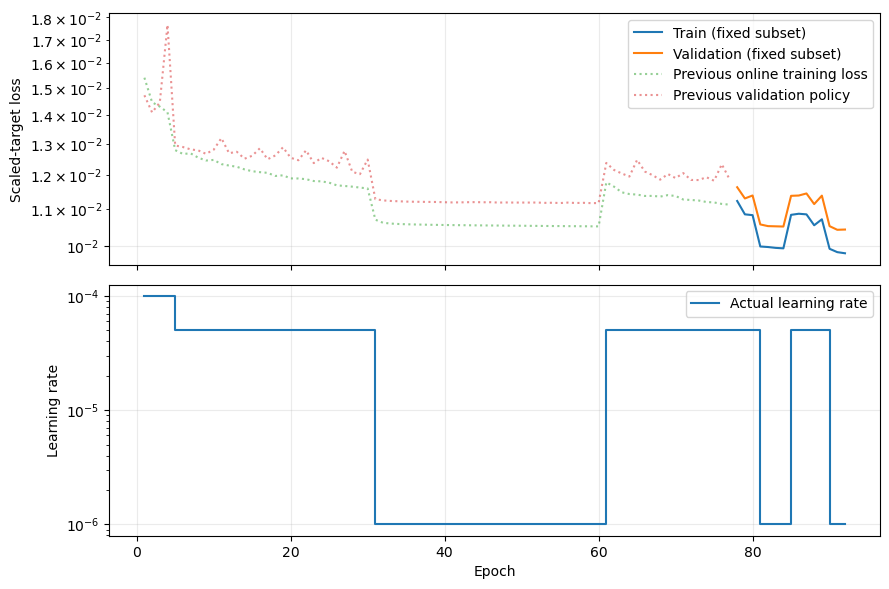

Last saved held-out test metrics: {
  "loss": 0.011334975914511465,
  "samples": 266000,
  "relative_l1": {
    "RBS": 0.009857900465627184
  },
  "best_epoch": 59,
  "checkpoint": "best.pt"
}


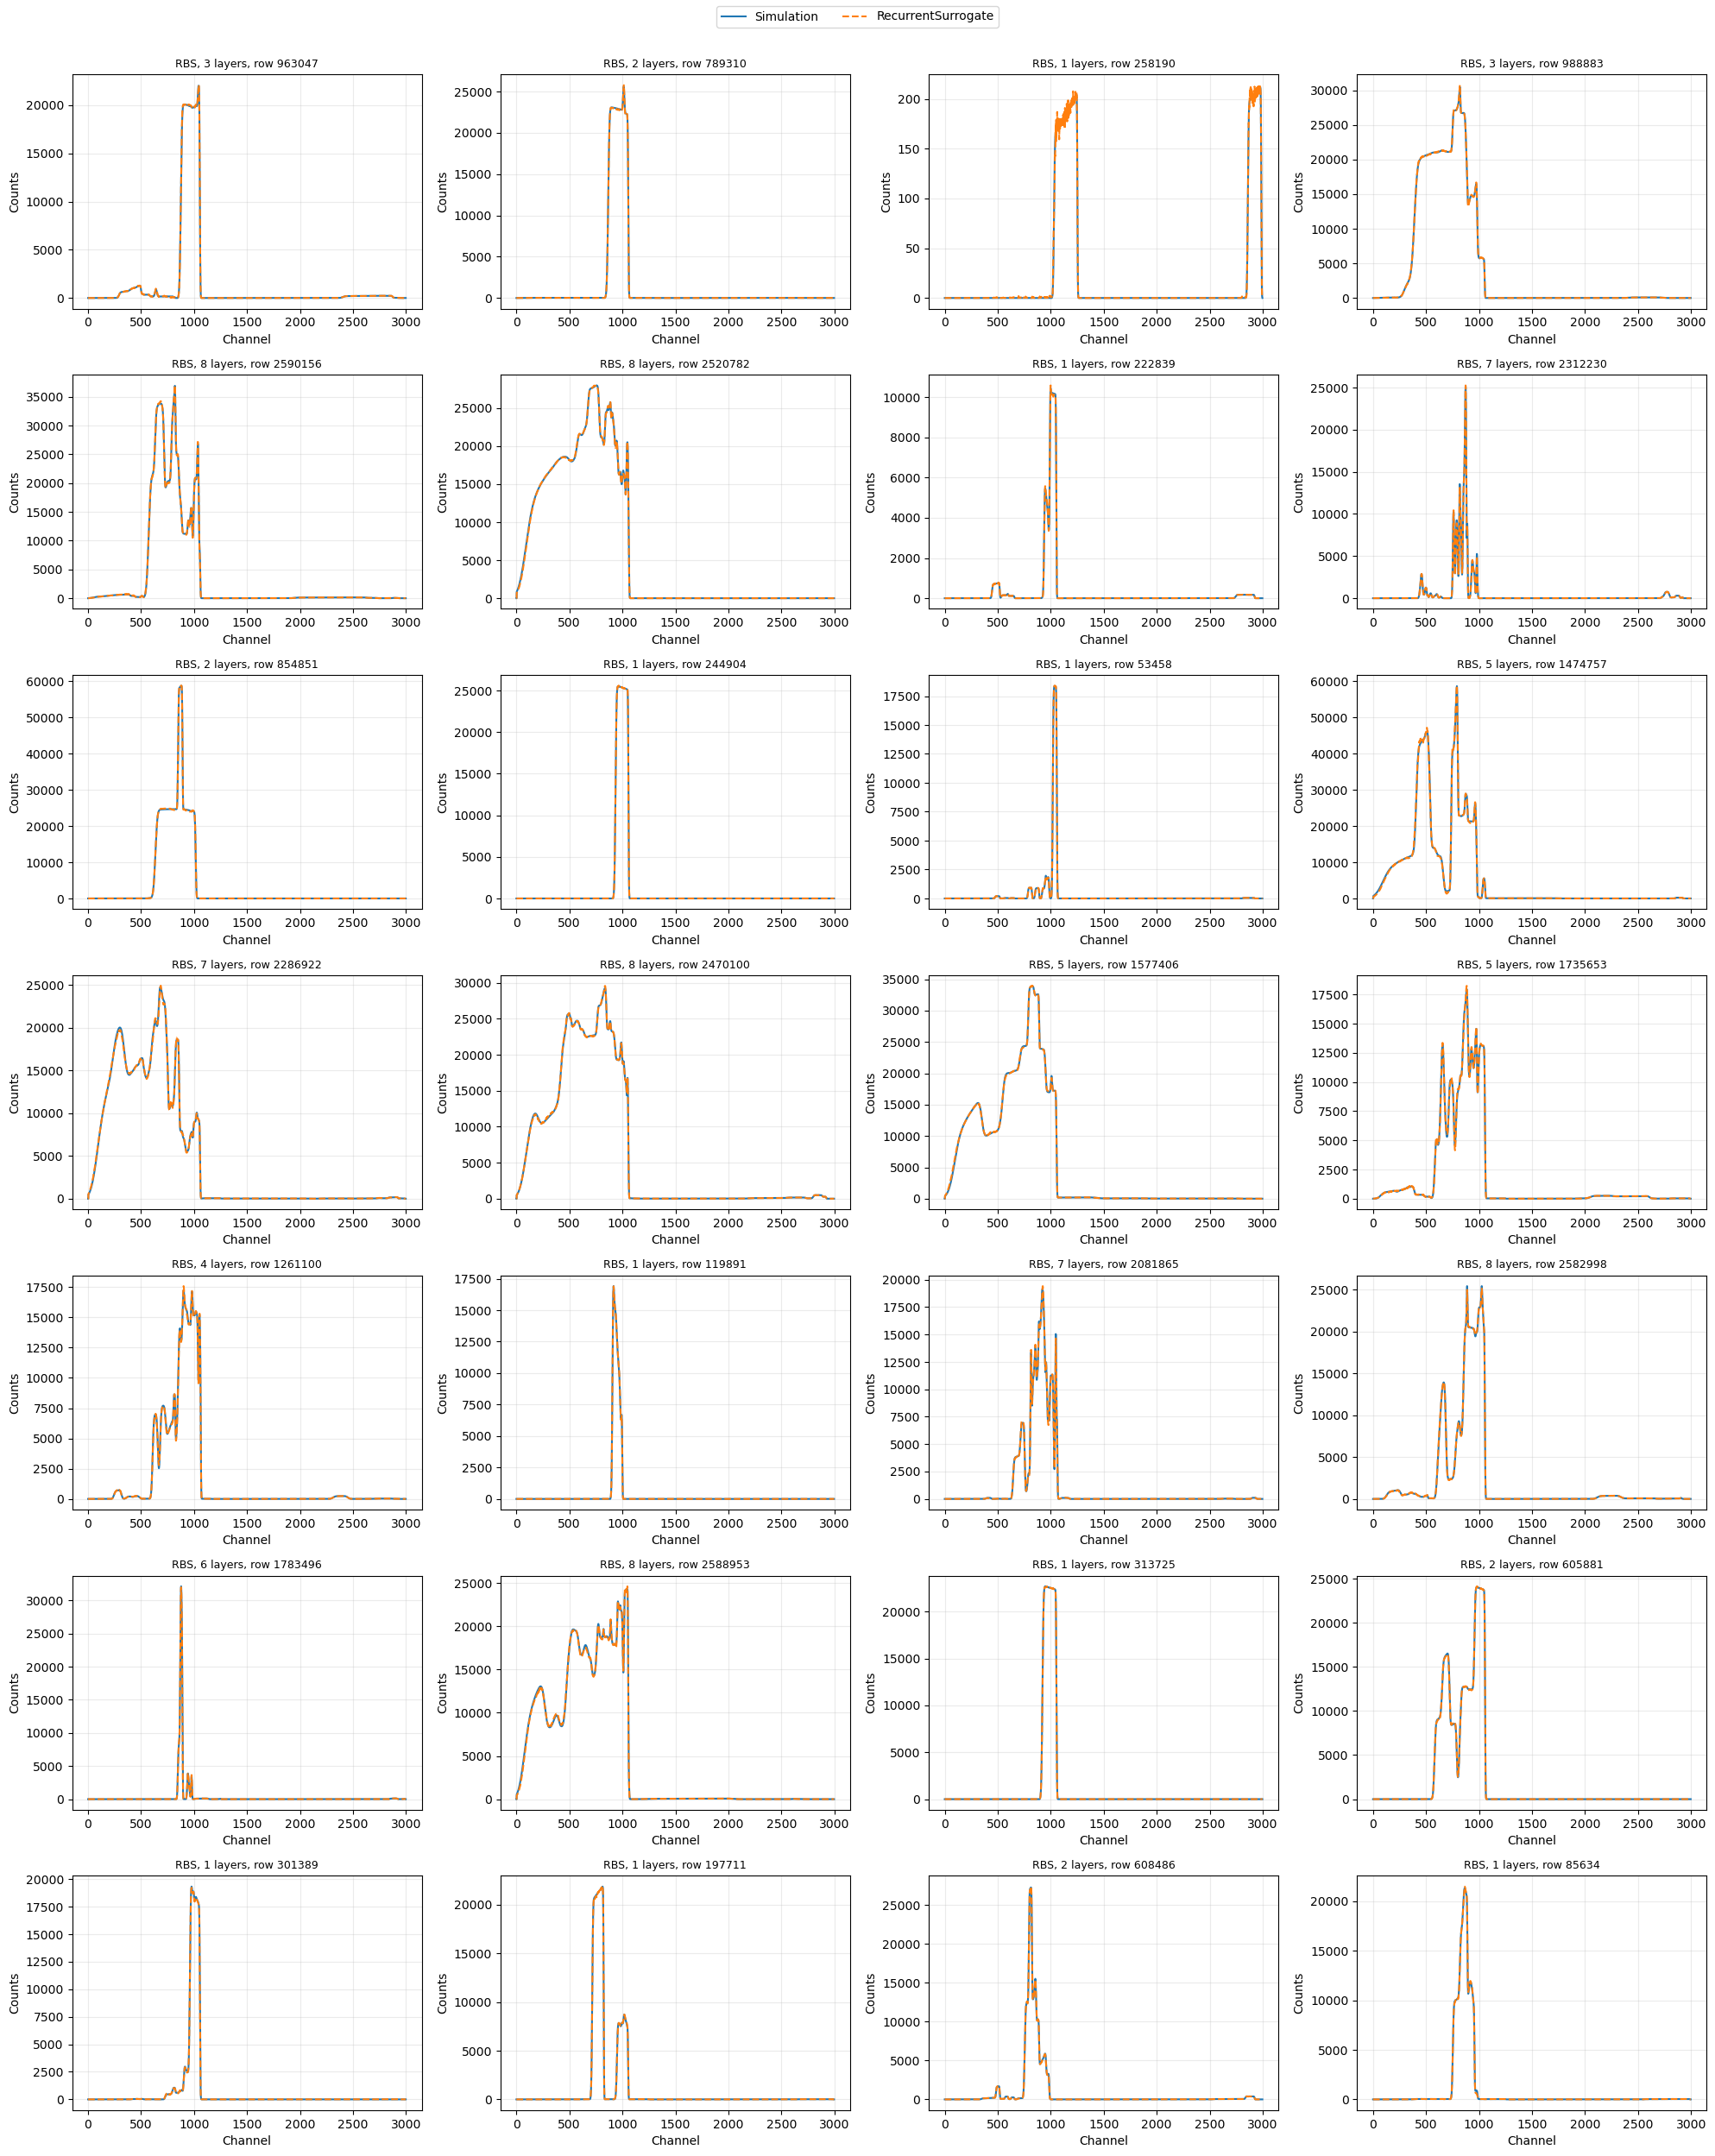

In [11]:
history = json.loads((RUN / "history.json").read_text())
metrics_path = RUN / "test-metrics.json"
metrics = json.loads(metrics_path.read_text()) if metrics_path.is_file() else None
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
epochs = [h["epoch"] for h in history]
axes[0].plot(epochs, [h["train_loss"] if h.get("train_loss_kind") == "fixed_subset" else np.nan
                      for h in history], label="Train (fixed subset)")
axes[0].plot(epochs, [h["validation_loss"] if h.get("train_loss_kind") == "fixed_subset" else np.nan
                      for h in history], label="Validation (fixed subset)")
if any(h.get("train_loss_kind") != "fixed_subset" for h in history):
    axes[0].plot(epochs, [h["train_loss"] if h.get("train_loss_kind") != "fixed_subset" else np.nan
                         for h in history], ":", alpha=.5, label="Previous online training loss")
    axes[0].plot(epochs, [h["validation_loss"] if h.get("train_loss_kind") != "fixed_subset" else np.nan
                         for h in history], ":", alpha=.5, label="Previous validation policy")
axes[0].set(ylabel="Scaled-target loss", yscale="log")
axes[0].legend()
axes[1].step(epochs, [h["learning_rate"] for h in history], where="post", label="Actual learning rate")
axes[1].set(xlabel="Epoch", ylabel="Learning rate", yscale="log")
axes[1].legend()
for axis in axes:
    axis.grid(alpha=.25)
fig.tight_layout()
plt.show()
print("Last saved held-out test metrics:", json.dumps(metrics, indent=2)
      if metrics is not None else "Not available yet; showing protected best predictions below.")

state = load_checkpoint(RUN / "best.pt")
validate_checkpoint_contract(state, manifest, cache_sha256=digest(CACHE / "manifest.json"))
best_model = make_model(manifest, state["model_options"])
best_model.load_state_dict(state["model_state"])
selected_device = config["training"]["device"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") if selected_device == "auto" else torch.device(selected_device)
best_model.to(device).eval()
# Held-out spectrum grid: exactly 7 rows x 4 columns.
PLOT_ROWS, PLOT_COLUMNS = 7, 4
PLOT_SEED = 42
panels = PLOT_ROWS * PLOT_COLUMNS
detectors = len(manifest["spectra"])
split_directory = RUN / "splits" if (RUN / "splits/manifest.json").is_file() else CACHE
test_indices = np.load(split_directory / "test_indices.npy", mmap_mode="r")
sample_count = min((panels + detectors - 1) // detectors, len(test_indices))
positions = np.random.default_rng(PLOT_SEED).choice(len(test_indices), sample_count, replace=False)
selected = np.asarray(test_indices[positions])
# Opening memory maps reads headers, not the complete dataset into RAM.
plot_features = np.load(CACHE / "features.npy", mmap_mode="r")
plot_targets = np.load(CACHE / "targets.npy", mmap_mode="r")
with torch.inference_mode():
    predicted = best_model(torch.from_numpy(plot_features[selected]).to(device)).cpu().numpy()
expected = np.array(plot_targets[selected])
offsets = np.cumsum([0] + [spec["channels"] for spec in manifest["spectra"]])
fig, axes = plt.subplots(PLOT_ROWS, PLOT_COLUMNS, figsize=(20, 25), squeeze=False)
for panel, axis in enumerate(axes.flat):
    row, detector = divmod(panel, detectors)
    if row >= len(selected):
        axis.set_visible(False)
        continue
    index = selected[row]
    spec = manifest["spectra"][detector]
    start, stop = offsets[detector:detector + 2]
    axis.plot(expected[row, start:stop] * spec["count_scale"], label="Simulation")
    axis.plot(predicted[row, start:stop] * spec["count_scale"], "--", label="RecurrentSurrogate")
    source = next(s for s in manifest["sources"] if s["start"] <= index < s["start"] + s["records"])
    axis.set_title(f"{spec['measurement']}, {source['layer_count']} layers, row {index}", fontsize=9)
    axis.set(xlabel="Channel", ylabel="Counts")
    axis.grid(alpha=.25)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2)
fig.tight_layout(rect=(0, 0, 1, .98))
plt.show()
del plot_features, plot_targets

## 6. Export one variable-layer model

Set `RUN_EXPORT=True` in the next cell to create one format-1 `forward.ibm` package.
The package has no fixed or maximum layer count. Its ONNX graph uses a runtime
Loop with dynamic batch/layer axes and skips trailing zero layers. Interior
zero layers remain masked no-ops. Training layer counts are provenance only.

The graph receives scaled elemental AD with one input per element per layer.
The C++ runtime converts physical thickness/fractions to AD, or accepts physical
AD directly with `model.predict_areal_density(ad)`. The AD factor is explicit
in `ForwardModelMetadata.input_transform` and applies once outside the graph.
Each detector restores count scaling in `output_transform`; `output_preparation` then rebins, scales exposure and optionally
applies pileup using requested real/live times. The `OUTPUT_PREPARATION` controls below default to
pileup enabled for RBS with tau=4e-7 seconds, matching the reference workflow.
Training targets must be pileup-free. Export checks the saved SIMNRA reference
checksum and its pileup flag when generation provenance is available.
Pileup is stored in package metadata and applied by C++ outside the ONNX graph.
It expands N channels to full 2*N-1 support. Use `predict_reference` or
`predict_reference_areal_density` to skip physical corrections. These export settings
do not change the training targets, cache, weights or learning-rate schedule.

ONNX/PyTorch comparisons cover batch sizes 1 and 3 and multiple layer counts,
including counts beyond training. Native verification additionally checks the
C++ inference path. For a SIMNRA-only extension, set `VERIFY_NATIVE=False`;
deployment later requires an ONNX-enabled build. Restart the kernel before
switching compiled extension builds. Existing package directories are never
overwritten.

In [16]:
from importlib import import_module, reload
import ibeamlab as ibl
from ibeamlab._engine import engine

# Check the already loaded binary before refreshing Python wrappers.
# Native extensions cannot be replaced safely inside a running kernel.
if not hasattr(engine(), "TransformPipeline"):
    raise RuntimeError(
        "This kernel loaded an older native extension: " + str(engine().__file__) +
        ". Keep training/data in this kernel; export in a fresh kernel/process "
        "using the current build. Reloading Python cannot update a loaded DLL."
    )

# Refresh only deployment wrappers, preserving loaded data and training state.
for module_name in ("ibeamlab.metadata", "ibeamlab.package", "ibeamlab.models", "ibeamlab.export"):
    reload(import_module(module_name))
ibl = reload(ibl)
from examples.ibeamnet import deployment as deployment_workflow
deployment_workflow = reload(deployment_workflow)

RUN_EXPORT = False
VERIFY_NATIVE = True  # Requires an ONNX-enabled extension.
EXPORT_DIRECTORY = ROOT / "examples/ibeamnet/packages"
EXPORT_OPSET = 17

# Physical inference operations, independently configured per detector.
# Numerical training transforms below are recovered from the training manifest.
OUTPUT_PREPARATION = {
    "RBS": {
        "rebin": True,
        "exposure_scale": True,
        "pileup": {"enabled": True, "targets_pileup_free": True, "tau_seconds": 4e-7},
    },
}
config["export"] = dict(output=EXPORT_DIRECTORY, opset=EXPORT_OPSET,
                        verify_native=VERIFY_NATIVE,
                        output_preparation=OUTPUT_PREPARATION)

# Inspect the same four-stage contract used by export; no data or weights reload.
export_metadata = deployment_workflow.build_export_metadata(manifest, config["export"])
export_metadata.validate()
stages = export_metadata.model
print("1. Input preparation:", stages.input_preparation.elements)
print("2. Input transform (fitted training AD scaling):", stages.input_transform.steps[0].factors)
for item in stages.output_transform:
    print("3. Output transform:", item.measurement, item.transform.direction, item.transform.steps[0].factors)
for item in stages.output_preparation:
    print("4. Output preparation:", item.measurement, item.steps)
print("Physical export controls:", OUTPUT_PREPARATION)

if RUN_EXPORT:
    reports = deployment_workflow.export(config, checkpoint=RUN / "best.pt")
    print(json.dumps(reports, indent=2))
    print("Packages:", config["export"]["output"])
else:
    print("Export skipped. Set RUN_EXPORT=True to export the durable best checkpoint.")


1. Input preparation: ['Li', 'Ni', 'Mn', 'Co', 'O', 'C', 'F', 'P', 'Cu', 'Al', 'Si', 'Na', 'Fe']
2. Input transform (fitted training AD scaling): [0.0001]
3. Output transform: RBS TransformDirection.INVERSE [0.01]
4. Output preparation: RBS [<_ibeamlab.Rebin object at 0x0000021708ABDDB0>, <_ibeamlab.ExposureScale object at 0x00000206CA5E7170>, <_ibeamlab.Pileup object at 0x00000206C08937B0>]
Physical export controls: {'RBS': {'rebin': True, 'exposure_scale': True, 'pileup': {'enabled': True, 'targets_pileup_free': True, 'tau_seconds': 4e-07}}}
Export skipped. Set RUN_EXPORT=True to export the durable best checkpoint.


In [17]:
export_metadata

ModelMetadata(model=ForwardModelMetadata(reference_setup=ExperimentalSetup(measurements=(Measurement(label='RBS', beam=Beam(particle='H', energy=2974.0, spread=0.0), detector=Detector(calibration_linear=2.63714, calibration_offset=0.0, calibration_quadratic=0.0, resolution=20.0, info=''), acquisition=Acquisition(particles_sr=1000000000000.0, real_time=0.001, live_time=0.001)),)), input_preparation=LayerInputSchema(elements=['Li', 'Ni', 'Mn', 'Co', 'O', 'C', 'F', 'P', 'Cu', 'Al', 'Si', 'Na', 'Fe']), output_spectra=<_ibeamlab.SpectraSchema object at 0x000002070CBFF870>, input_transform=<_ibeamlab.TransformPipeline object at 0x00000206A68F68F0>, output_transform=[<_ibeamlab.SpectrumTransform object at 0x00000206CA867A70>], output_preparation=[<_ibeamlab.SpectrumProcessing object at 0x00000206C5119370>]), input_name='inputs', output_name='outputs', provenance='')